# USOvernight Pitch EDA: should you own US small caps only overnight?

**The pattern.** US equity returns accrue overnight (close → open), not intraday (Cliff, Cooper & Gulen 2008; Lou,
Polk & Skouras 2019). **The mechanism.** Berkman, Koch, Tuttle & Zhang (*JFQA* 2012), "Paying attention: overnight
returns and the hidden cost of buying at the open": attention-driven retail investors place orders outside market hours
that execute at the open, pushing opening prices up. The pressure reverses during the day, more so in smaller, retail-heavy
stocks. The open is a predictable, recurring demand shock; whoever **sells into the opening auction** is paid for it.

**The trade.** Buy the ETF in the closing auction (MOC), sell it in the opening auction (MOO). Out of the market
during the day. Cost about 0.5bp/side for an ETF in the auctions (commission + fees, no spread); 1bp/day used, 2bp
stress.

**Questions.**

*Part A: exploratory analysis (no trading rule yet)*
1. Data quality: how often are opens stale (open = prior close), and does Yahoo's daily open match a tradable print?
2. How are overnight and intraday returns distributed (mean, median, hit rate, volatility, skew, tails)?
3. Is the split stable through time, or concentrated in a few years?
4. What does the average day look like after the open (5-minute bars)? Does the opening print revert?
5. Does a bigger overnight gap revert more intraday, and is there a weekday pattern?

*Part B: backtest*
6. Does overnight-only beat buy-and-hold, risk-adjusted, for small-cap ETFs, in-sample (≤2010) and out-of-sample (2011–)?
7. Is it broad across small-cap ETFs (different index families), and what about large caps?
8. Is the edge in the opening print itself (sell MOO), or does it survive later exits? (5-minute bars, 2020–)
9. Is it a small-cap *overnight* premium relative to SPY's overnight, or mainly the avoidance of the small-cap intraday drag?

**Data.** Yahoo daily OHLC (`collect.py`), small-cap ETFs (IWM, IWO, IWN, IWC, IJR, IJS, IJT, VB, VTWO, SCHA), large-cap
and sector ETFs for comparison; Twelve Data 5-minute bars 2020– (`collect_intraday.py`). Close → open returns are
dividend-adjusted (ex-dates fall at the open).

**Look-ahead checklist.** No signal: the position is the same every day (long overnight, flat intraday). The only
assumption is fills at the official closing / opening auction prices.

## 1. Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
SPLIT = pd.Timestamp("2011-01-01")
d = pd.concat([pd.read_csv("data/etfs.csv", parse_dates=["date"]), pd.read_csv("data/smallcap_etfs.csv", parse_dates=["date"])]).drop_duplicates(["date", "ticker"])
def legs(t):
    g = d[d.ticker == t].set_index("date").sort_index(); f = g.adj_close / g.close
    on = np.log(g.open * f / (g.close.shift(1) * f.shift(1))) * 1e4
    idr = np.log(g.close / g.open) * 1e4
    bh = np.log(g.adj_close / g.adj_close.shift(1)) * 1e4
    stale = g.open == g.close.shift(1)
    return pd.DataFrame({"on": on, "id": idr, "bh": bh, "stale": stale}).dropna()
SMALL = ["IWM", "IWO", "IWN", "IWC", "IJR", "IJS", "IJT", "VB", "VTWO", "SCHA"]
LARGE = ["SPY", "QQQ", "DIA", "MDY", "XLK", "XLF", "XLE", "XLV", "XLI"]
L = {t: legs(t) for t in SMALL + LARGE}
print({t: str(v.index.min().date()) for t, v in L.items()})

{'IWM': '2000-05-30', 'IWO': '2000-07-31', 'IWN': '2000-07-31', 'IWC': '2005-08-17', 'IJR': '2000-05-30', 'IJS': '2000-07-31', 'IJT': '2000-07-31', 'VB': '2004-02-02', 'VTWO': '2010-09-23', 'SCHA': '2009-11-04', 'SPY': '1993-02-01', 'QQQ': '1999-03-11', 'DIA': '1998-01-21', 'MDY': '1995-05-05', 'XLK': '1998-12-23', 'XLF': '1998-12-23', 'XLE': '1998-12-23', 'XLV': '1998-12-23', 'XLI': '1998-12-23'}


# Part A: exploratory analysis
## 2. Data quality
**What this does.** Share of days whose open equals the prior close (a sign of a stale or filled-in open, common in
older Yahoo data), by five-year bucket. Then, for 2020– where 5-minute bars exist, the gap between Yahoo's daily open
and the first 5-minute bar's open (Twelve Data, consolidated tape). If the two disagree often, the daily "open" may not be
a price one could trade at.

In [2]:
Q = pd.DataFrame({t: L[t].stale.groupby(L[t].index.year // 5 * 5).mean() * 100 for t in ["IWM", "IWO", "IJR", "VB", "IWC", "SPY", "QQQ"]})
print("stale opens, % of days:"); print(Q.loc[1995:].round(1).to_string())
def bars(t):
    x = pd.read_csv(f"data/intraday/{t}.csv", parse_dates=["datetime"]); x["d"] = x.datetime.dt.normalize(); x["hm"] = x.datetime.dt.strftime("%H:%M")
    return {k: x.pivot_table(index="d", columns="hm", values=k) for k in ["open", "close", "volume"]}
BARS = {t: bars(t) for t in ["IWM", "VB", "IJR", "SPY"]}
rows = []
for t, b in BARS.items():
    op = d[d.ticker == t].set_index("date").open.reindex(b["open"].index)
    dv = (np.log(b["open"]["09:30"] / op) * 1e4).dropna()
    rows.append({"ETF": t, "days": len(dv), "mean first-bar − daily open bp": dv.mean(), "% days |gap| > 2bp": (dv.abs() > 2).mean() * 100,
                 "% days |gap| > 10bp": (dv.abs() > 10).mean() * 100, "first-bar volume share %": (b["volume"]["09:30"] / b["volume"].sum(1)).median() * 100})
print(); print(pd.DataFrame(rows).round(2).to_string(index=False))

stale opens, % of days:
      IWM  IWO  IJR   VB  IWC  SPY  QQQ
date                                   
1995  NaN  NaN  NaN  NaN  NaN  3.2  3.9
2000  4.1  3.8  3.3  3.0  NaN  1.0  1.0
2005  1.3  2.2  2.1  2.1  2.3  1.0  2.1
2010  1.0  1.3  1.6  1.7  1.8  0.6  1.6
2015  1.5  1.6  1.7  1.6  1.5  2.0  1.0
2020  0.4  0.3  1.0  0.4  1.5  0.3  0.2
2025  0.0  0.2  0.7  0.7  1.1  0.0  0.0



ETF  days  mean first-bar − daily open bp  % days |gap| > 2bp  % days |gap| > 10bp  first-bar volume share %
IWM  1672                           -0.18               20.39                11.00                      5.36
 VB  1675                           -3.81               31.04                22.33                      2.87
IJR  1676                           -0.99               33.11                22.55                      2.88
SPY  1677                           -0.08               12.46                 4.17                      4.80


**Interpretation.**
- **Stale opens are a pre-2005 problem.** They run 3–4% of days in 2000–04 and fall to about 1% or less after 2020.
  Results that lean on early history should be read with this in mind.
- **IWM and SPY: the daily open matches the tape on average** (mean gap to the first 5-minute bar under 0.2bp),
  though the two still differ by more than 10bp on 11% (IWM) and 4% (SPY) of days.
- **VB and IJR do not.** VB's daily open sits 3.8bp *above* the first traded price on average, and the two differ by
  more than 2bp on about 30% of days. That gap lands directly in VB's overnight return. VB's strong numbers in Part B
  should therefore be discounted; IWM is the cleanest test.
- The first 5 minutes carry only about 3–5% of daily volume, so the opening auction is thin relative to the close.

## 3. Distribution of the two legs
**What this does.** For each ETF and era: mean, median, volatility, skew, excess kurtosis and hit rate (% of positive
days) of the overnight (close → open) and intraday (open → close) log returns in bp, plus each leg's share of total
variance. Histograms for IWM.

ETF   era       leg  mean  median    std  skew  ex-kurt  hit %  var share %
IWM ≤2010 overnight  5.30    6.10  82.50  0.01    18.58  56.32        23.64
IWM ≤2010  intraday -2.80    2.72 148.25 -0.17     4.76  50.77        76.36
IWM 2011– overnight  4.76    6.98  84.01 -0.63    15.26  55.54        37.01
IWM 2011–  intraday -1.06    3.11 109.59 -0.09     3.72  51.13        62.99
IWO ≤2010 overnight  5.21    8.19  95.38 -0.33    12.08  55.64        27.68
IWO ≤2010  intraday -4.46    1.66 154.16 -0.08     3.13  50.23        72.32
IWO 2011– overnight  4.93    8.64  86.13 -1.37    18.35  56.78        34.28
IWO 2011–  intraday -1.16    3.36 119.26 -0.02     3.80  51.36        65.72
IJR ≤2010 overnight  6.22    6.89  86.39  2.15    82.41  57.00        26.83
IJR ≤2010  intraday -2.97    1.54 142.69 -0.51    10.32  50.32        73.17
IJR 2011– overnight  4.42    6.71  79.83 -1.47    25.61  56.07        35.61
IJR 2011–  intraday -0.36    1.68 107.34  0.12     4.45  50.71        64.39
 VB ≤2010 ov

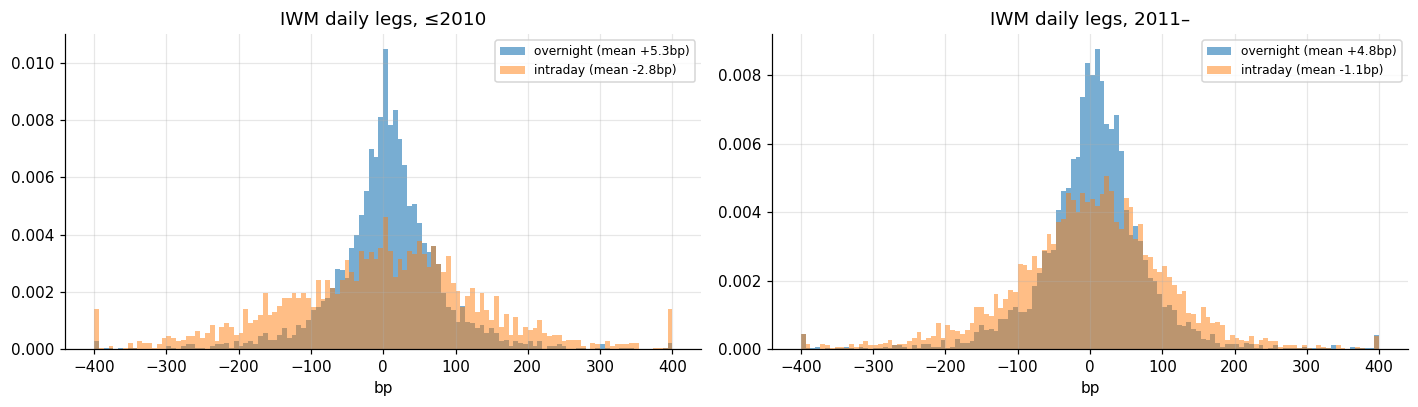

In [3]:
rows = []
for t in ["IWM", "IWO", "IJR", "VB", "IWC", "SPY", "QQQ"]:
    v = L[t]
    for per, m in [("≤2010", v.index < SPLIT), ("2011–", v.index >= SPLIT)]:
        x = v[m]
        for leg, nm in [("on", "overnight"), ("id", "intraday")]:
            s = x[leg]
            rows.append({"ETF": t, "era": per, "leg": nm, "mean": s.mean(), "median": s.median(), "std": s.std(), "skew": stats.skew(s),
                         "ex-kurt": stats.kurtosis(s), "hit %": (s > 0).mean() * 100, "var share %": s.var() / (x.on.var() + x.id.var()) * 100})
print(pd.DataFrame(rows).round(2).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, (per, m) in zip(ax, [("≤2010", L["IWM"].index < SPLIT), ("2011–", L["IWM"].index >= SPLIT)]):
    x = L["IWM"][m]; bins = np.linspace(-400, 400, 121)
    a.hist(x.on.clip(-400, 400), bins=bins, alpha=0.6, density=True, label=f"overnight (mean {x.on.mean():+.1f}bp)")
    a.hist(x.id.clip(-400, 400), bins=bins, alpha=0.5, density=True, label=f"intraday (mean {x.id.mean():+.1f}bp)")
    a.set_title(f"IWM daily legs, {per}"); a.set_xlabel("bp"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.**
- **The overnight leg is consistently positive in small caps.** Mean +4 to +10bp/day, median above the mean, and
  positive on 55–59% of nights in both eras. The intraday leg is negative on average (−0.4 to −7bp) with a hit rate near
  50%.
- **Large caps changed after 2010.** SPY and QQQ intraday flipped from negative to positive (+1.9 / +2.2bp), with hit
  rates of 54%. That matches Part B, where overnight-only stops beating holding large caps.
- **Overnight carries less risk than its share of return.** It holds a quarter to a third of total variance but earns
  all of the return. Since 2011 it is negatively skewed (−0.6 to −1.5) with fat tails (excess kurtosis 15–25): the
  overnight risk is gap-down crashes (COVID, tariff shocks).

## 4. Stability through time
**What this does.** Rolling three-year mean of each leg, annualised (% per year), for the small-cap basket and SPY.
Tests whether the split is persistent or the product of a few episodes.

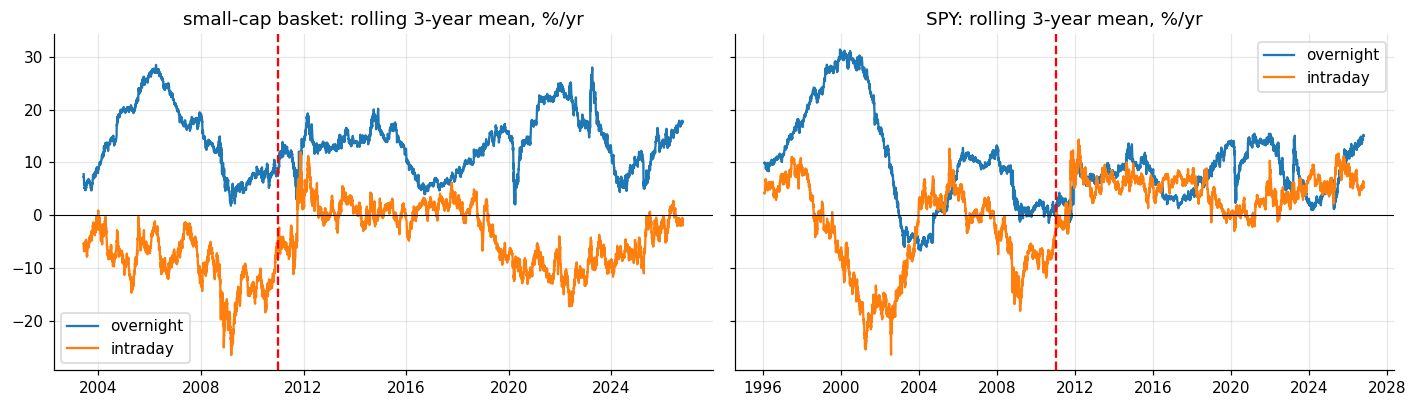

calendar-year sums, %:
date              2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
basket overnight -11.2   5.4  31.5  23.9  24.8  14.0  18.1 -11.6  16.3  18.2   5.0  12.5  24.4  11.0   1.8   4.1  18.8  12.9  15.2  24.1  33.4  -8.1  11.6  25.9   4.7  10.5
basket intraday   14.3 -25.0   4.3  -5.7 -19.0   1.1 -19.9 -29.9   8.0   6.1  -8.2   3.3   9.2  -5.6  -5.7  16.1  -5.5 -24.0   6.7  -8.5 -16.0 -13.1   3.3 -15.5   5.8   2.3
years with overnight > intraday: 23 of 26


In [4]:
ON = pd.DataFrame({t: L[t].on for t in SMALL}).mean(1); ID = pd.DataFrame({t: L[t].id for t in SMALL}).mean(1)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, (nm, o, i) in zip(ax, [("small-cap basket", ON, ID), ("SPY", L["SPY"].on, L["SPY"].id)]):
    a.plot(o.rolling(756).mean() * 2.52, label="overnight"); a.plot(i.rolling(756).mean() * 2.52, label="intraday")
    a.axhline(0, c="k", lw=0.7); a.axvline(SPLIT, c="r", ls="--"); a.set_title(f"{nm}: rolling 3-year mean, %/yr"); a.legend()
plt.tight_layout(); plt.show()
yrs = pd.DataFrame({"basket overnight": ON.groupby(ON.index.year).sum() / 100, "basket intraday": ID.groupby(ID.index.year).sum() / 100}).loc[2001:]
print("calendar-year sums, %:"); print(yrs.round(1).T.to_string())
print("years with overnight > intraday:", (yrs["basket overnight"] > yrs["basket intraday"]).sum(), "of", len(yrs))

**Interpretation.**
- **The overnight leg is the stable one.** The basket's overnight return is positive in 23 of 26 calendar years
  (negative in 2001, 2008, 2022: market crashes), and overnight beats intraday in 23 of 26 years.
- **The intraday leg is not uniformly negative.** It was deeply negative in 2002–08 and 2018–24, but roughly flat in
  2011–2017 (mixed signs, sum about +4% over seven years). So the overnight-only advantage concentrates in two long
  regimes, not every year, and Part B's out-of-sample result leans on 2018+.
- SPY's intraday leg has been positive in most windows since 2011, which is why the trade is a small-cap trade.

## 5. The average day after the open (2020–, 5-minute bars)
**What this does.** Average cumulative log return from the official daily open to each 5-minute close, across days.
If retail buying inflates the opening print (the mechanism), the path should drift down from the open, most steeply early.

IWM bp from open at {'09:30': -0.59, '09:55': -0.93, '10:25': -1.66, '11:55': -1.01, '13:55': -1.45, '15:55': -2.52}
VB bp from open at {'09:30': -0.63, '09:55': -2.44, '10:25': -2.87, '11:55': -2.56, '13:55': -2.86, '15:55': -4.06}
IJR bp from open at {'09:30': 1.58, '09:55': -0.01, '10:25': 0.18, '11:55': 0.73, '13:55': 0.61, '15:55': -0.76}
SPY bp from open at {'09:30': 0.33, '09:55': 0.94, '10:25': 1.15, '11:55': 1.59, '13:55': 1.77, '15:55': 1.86}


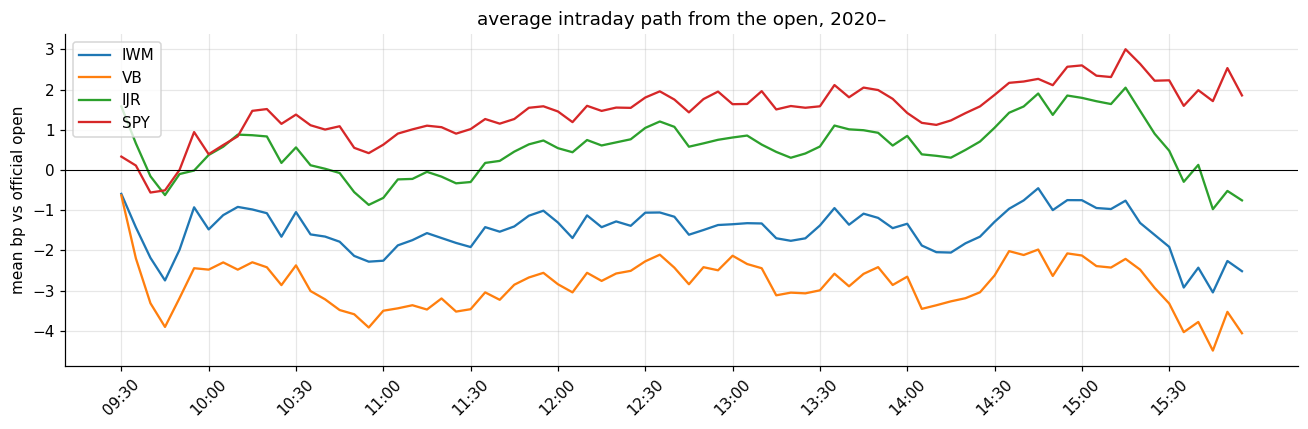

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
for t, b in BARS.items():
    op = d[d.ticker == t].set_index("date").open.reindex(b["close"].index)
    path = (np.log(b["close"].div(op, axis=0)) * 1e4).mean()
    ax.plot(path.index, path.values, label=t)
    print(t, "bp from open at", {h: round(float(path[h]), 2) for h in ["09:30", "09:55", "10:25", "11:55", "13:55", "15:55"]})
ax.axhline(0, c="k", lw=0.7); ax.set_xticks(path.index[::6]); ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("mean bp vs official open"); ax.set_title("average intraday path from the open, 2020–"); ax.legend(); plt.tight_layout(); plt.show()

**Interpretation.**
- **IWM and VB drift down from the open** (IWM −1.7bp by 10:30, −2.5bp by the close; VB −2.9 / −4.1). About two
  thirds of IWM's intraday loss arrives in the first hour, consistent with the opening print being inflated and
  reverting.
- **SPY drifts up all day** (+1.9bp), so in large caps there is no opening premium to sell.
- **IJR is noisier:** its first bar sits above the open, then it falls back to about zero. It is the weakest small-cap
  ETF in Part B.
- The averages are small (a few bp) relative to daily volatility (about 100bp). This is a small daily edge that only
  shows up over many days, and it is why costs matter.

## 6. Does a bigger gap revert more? Weekday pattern
**What this does.** Splits days into quintiles by the overnight return and shows the mean intraday return that follows
in each, plus the correlation of the two legs. Then mean overnight and intraday return by weekday (2011–).

IWM ≤2010: corr(overnight, intraday) -0.049
IJR ≤2010: corr(overnight, intraday) -0.131
VB ≤2010: corr(overnight, intraday) -0.082
SPY ≤2010: corr(overnight, intraday) -0.014
IWM 2011–: corr(overnight, intraday) +0.011
IJR 2011–: corr(overnight, intraday) +0.040
VB 2011–: corr(overnight, intraday) +0.047
SPY 2011–: corr(overnight, intraday) +0.025


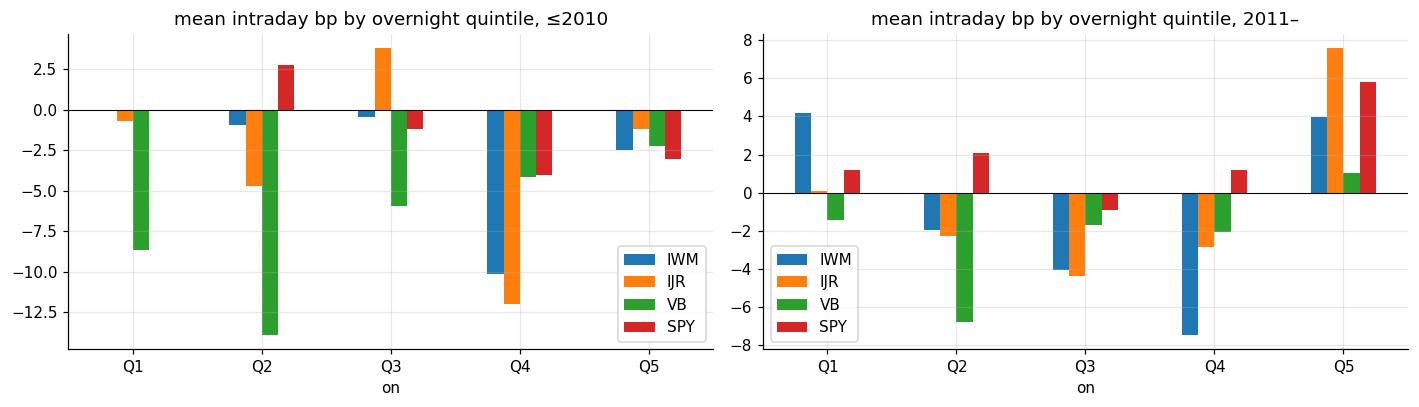


mean bp by weekday, 2011–:
          IWM                IJR                SPY         
    overnight intraday overnight intraday overnight intraday
Mon       3.0      0.0       1.0      2.1      -0.8      4.9
Tue       8.4      0.6       8.3      1.9       6.7      1.5
Wed       6.4     -6.6       6.8     -7.3       5.7      0.3
Thu       1.4      0.3       0.7      1.5       1.2      1.8
Fri       4.4      0.4       4.9      0.3       3.8      1.2


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, (per, cut) in zip(ax, [("≤2010", lambda i: i < SPLIT), ("2011–", lambda i: i >= SPLIT)]):
    tab = {}
    for t in ["IWM", "IJR", "VB", "SPY"]:
        x = L[t][cut(L[t].index)]; q = pd.qcut(x.on, 5, labels=[f"Q{k}" for k in range(1, 6)])
        tab[t] = x.id.groupby(q).mean()
        print(f"{t} {per}: corr(overnight, intraday) {x.on.corr(x.id):+.3f}")
    pd.DataFrame(tab).plot.bar(ax=a, rot=0); a.set_title(f"mean intraday bp by overnight quintile, {per}"); a.axhline(0, c="k", lw=0.7)
plt.tight_layout(); plt.show()
wd = {}
for t in ["IWM", "IJR", "SPY"]:
    x = L[t][L[t].index >= SPLIT]
    wd[(t, "overnight")] = x.on.groupby(x.index.dayofweek).mean(); wd[(t, "intraday")] = x.id.groupby(x.index.dayofweek).mean()
W = pd.DataFrame(wd); W.index = ["Mon", "Tue", "Wed", "Thu", "Fri"]
print("\nmean bp by weekday, 2011–:"); print(W.round(1).to_string())

**Interpretation.**
- **No gap-size reversal.** The correlation of the overnight and intraday legs is about zero (−0.13 to +0.05), and the
  intraday return does not fall steadily across overnight quintiles. The intraday drag is a level effect present on
  ordinary days, not a reversal of large gaps. That fits an always-on opening demand from retail better than an
  overreaction story, but it also means there is no gap-based filter to improve the trade.
- **Weekdays: the small-cap intraday drag is concentrated on Wednesdays** (IWM −6.6bp, IJR −7.3bp; other days about
  0 to +2bp). Monday's overnight (the weekend) is the weakest for SPY. A Wednesday-only drag fits the retail-at-the-open
  story less well than a drag spread across all days. It is a warning sign for the mechanism, worth explaining before
  the pitch relies on it.

**EDA takeaways for the backtest.** The overnight leg is the stable, positive part of small-cap returns; the
intraday leg is negative in most long windows but not all, and since 2011 its drag sits mostly on Wednesdays; the opening print appears to sit slightly high in IWM and
VB; and VB's (and partly IJR's) daily opens do not match the tape. Part B tests whether this is large enough to beat
holding after costs, and leans on IWM and the basket rather than VB alone.

# Part B: backtest

## 7. Where the return is earned (all ETFs)
**What this does.** Mean overnight and intraday log returns (bp/day) per ETF and era, with t-stats.

In [7]:
rows = []
for t, v in L.items():
    for per, m in [("≤2010", v.index < SPLIT), ("2011–", v.index >= SPLIT)]:
        x = v[m]
        if len(x) < 500: continue
        rows.append({"ETF": t, "group": "small" if t in SMALL else "large", "era": per, "overnight bp": x.on.mean(),
                     "t on": x.on.mean() / x.on.std() * np.sqrt(len(x)), "intraday bp": x.id.mean(), "t id": x.id.mean() / x.id.std() * np.sqrt(len(x))})
print(pd.DataFrame(rows).round(2).to_string(index=False))

 ETF group   era  overnight bp  t on  intraday bp  t id
 IWM small ≤2010          5.30  3.32        -2.80 -0.98
 IWM small 2011–          4.76  3.57        -1.06 -0.61
 IWO small ≤2010          5.21  2.80        -4.46 -1.48
 IWO small 2011–          4.93  3.61        -1.16 -0.61
 IWN small ≤2010          3.68  2.48        -0.16 -0.06
 IWN small 2011–          5.37  4.20        -1.87 -1.08
 IWC small ≤2010          7.67  3.24        -7.30 -1.67
 IWC small 2011–          6.43  4.80        -2.76 -1.45
 IJR small ≤2010          6.22  3.72        -2.97 -1.08
 IJR small 2011–          4.42  3.49        -0.36 -0.21
 IJS small ≤2010          3.05  1.97         0.37  0.13
 IJS small 2011–          4.56  3.72        -0.71 -0.40
 IJT small ≤2010          4.10  2.45        -1.51 -0.57
 IJT small 2011–          3.97  3.08         0.16  0.09
  VB small ≤2010          9.77  4.50        -6.97 -1.99
  VB small 2011–          6.24  5.13        -2.19 -1.37
VTWO small 2011–          5.87  4.34        -2.1

## 8. Overnight-only vs buy-and-hold
**What this does.** Net overnight-only P&L (1bp/day) regressed on the ETF's own close-to-close return (HAC errors):
the intercept is the return earned beyond the market exposure the overnight position carries. Sharpe of both, by era,
with 2bp stress.

In [8]:
rows = []
for t, v in L.items():
    for cost in [1.0, 2.0]:
        for per, m in [("≤2010", v.index < SPLIT), ("2011–", v.index >= SPLIT), ("2020–", v.index >= "2020-01-01")]:
            x = v[m]
            if len(x) < 500: continue
            p = x.on - cost
            f = sm.OLS(p, sm.add_constant(x.bh)).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
            rows.append({"ETF": t, "group": "small" if t in SMALL else "large", "cost": cost, "era": per,
                         "ON-only Sharpe": p.mean() / p.std() * np.sqrt(252), "B&H Sharpe": x.bh.mean() / x.bh.std() * np.sqrt(252),
                         "alpha %/yr": f.params.const * 252 / 100, "t alpha": f.tvalues.const, "beta": f.params.iloc[1]})
A = pd.DataFrame(rows)
print(A[A.cost == 1.0].round(2).to_string(index=False))
print("\n2bp/day stress, small caps:")
print(A[(A.cost == 2.0) & (A.group == "small")].round(2).to_string(index=False))

 ETF group  cost   era  ON-only Sharpe  B&H Sharpe  alpha %/yr  t alpha  beta
 IWM small   1.0 ≤2010            0.83        0.24        9.43     2.90  0.22
 IWM small   1.0 2011–            0.71        0.42        6.02     2.43  0.37
 IWM small   1.0 2020–            0.79        0.34        9.52     2.12  0.42
 IWO small   1.0 ≤2010            0.70        0.07       10.12     2.76  0.26
 IWO small   1.0 2011–            0.73        0.41        6.67     2.44  0.34
 IWO small   1.0 2020–            0.63        0.29        7.67     1.54  0.38
 IWN small   1.0 ≤2010            0.56        0.34        4.94     1.66  0.21
 IWN small   1.0 2011–            0.86        0.40        7.81     3.39  0.36
 IWN small   1.0 2020–            0.96        0.35       11.76     2.82  0.40
 IWC small   1.0 ≤2010            1.21        0.03       16.59     3.50  0.22
 IWC small   1.0 2011–            1.02        0.40       10.62     3.92  0.33
 IWC small   1.0 2020–            1.07        0.35       14.78  

**What this does.** An equal-weight portfolio of the small-cap ETFs available at each date (diversifies away
fund-specific opening noise), overnight-only vs buy-and-hold.

small-cap basket ≤2010: ON-only Sharpe +0.96 vs B&H +0.27 | alpha +10.2%/yr (t +3.54)
small-cap basket 2011–: ON-only Sharpe +0.84 vs B&H +0.45 | alpha +7.1%/yr (t +2.99)


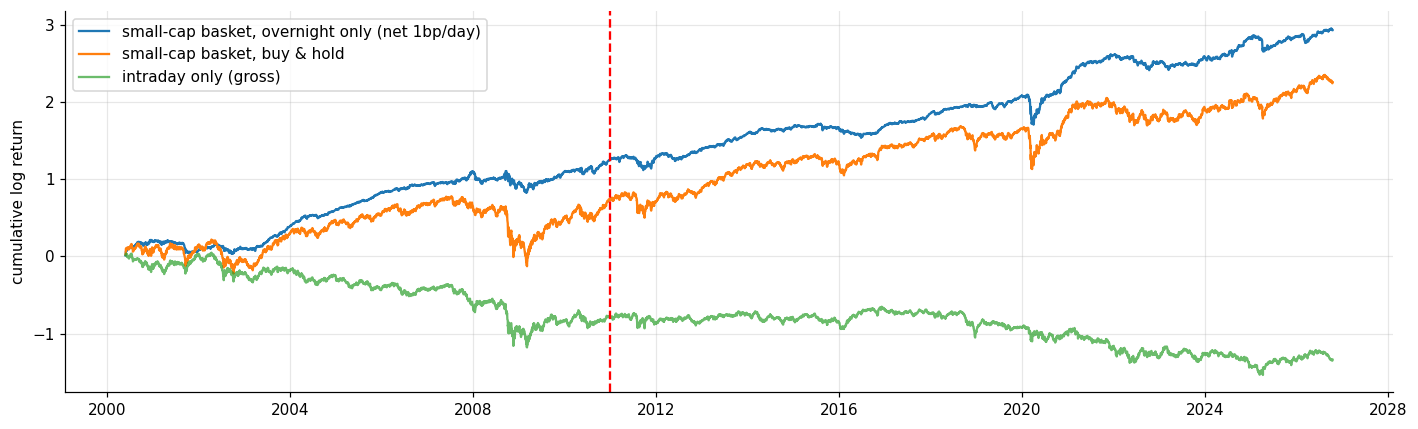

ON-only basket, % per year: {2000: 20.5, 2001: -13.7, 2002: 2.8, 2003: 29.0, 2004: 21.3, 2005: 22.3, 2006: 11.5, 2007: 15.6, 2008: -14.2, 2009: 13.8, 2010: 15.7, 2011: 2.4, 2012: 10.0, 2013: 21.9, 2014: 8.5, 2015: -0.7, 2016: 1.6, 2017: 16.2, 2018: 10.4, 2019: 12.7, 2020: 21.6, 2021: 30.8, 2022: -10.6, 2023: 9.1, 2024: 23.3, 2025: 2.2, 2026: 8.5}


In [9]:
P = pd.DataFrame({t: L[t].on - 1.0 for t in SMALL}); B = pd.DataFrame({t: L[t].bh for t in SMALL})
pon, pbh = P.mean(1), B.mean(1)
k = pd.DataFrame({"p": pon, "b": pbh}).dropna()
for per, m in [("≤2010", k.index < SPLIT), ("2011–", k.index >= SPLIT)]:
    z = k[m]; f = sm.OLS(z.p, sm.add_constant(z.b)).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    print(f"small-cap basket {per}: ON-only Sharpe {z.p.mean() / z.p.std() * np.sqrt(252):+.2f} vs B&H {z.b.mean() / z.b.std() * np.sqrt(252):+.2f} | alpha {f.params.const * 252 / 100:+.1f}%/yr (t {f.tvalues.const:+.2f})")
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot((k.p / 1e4).cumsum(), label="small-cap basket, overnight only (net 1bp/day)")
ax.plot((k.b / 1e4).cumsum(), label="small-cap basket, buy & hold")
ax.plot((pd.DataFrame({t: L[t].id for t in SMALL}).mean(1) / 1e4).cumsum(), label="intraday only (gross)", alpha=0.7)
ax.axvline(SPLIT, c="r", ls="--"); ax.set_ylabel("cumulative log return"); ax.legend(); plt.tight_layout(); plt.show()
yr = k.groupby(k.index.year).p.sum() / 100
print("ON-only basket, % per year:", yr.round(1).to_dict())

## 9. Is the edge in the opening print? (2020–, 5-minute bars)
**What this does.** Re-computes the overnight return with later exits (first 5-minute bar's open, 09:35, 10:00, 10:30)
instead of the official open, alpha vs buy-and-hold, net 1bp.

In [10]:
for t in ["IWM", "VB", "IJR", "SPY"]:
    g = d[d.ticker == t].set_index("date").sort_index(); f = g.adj_close / g.close
    x = pd.read_csv(f"data/intraday/{t}.csv", parse_dates=["datetime"]); x["d"] = x.datetime.dt.normalize(); x["hm"] = x.datetime.dt.strftime("%H:%M")
    o = x.pivot_table(index="d", columns="hm", values="open"); c = x.pivot_table(index="d", columns="hm", values="close")
    idx = c.index.intersection(g.index)
    prevc = (g.close.shift(1) * f.shift(1) / f).reindex(idx)
    bh = (np.log(g.adj_close / g.adj_close.shift(1)) * 1e4).reindex(idx)
    line = f"{t}: "
    for nm, px in {"official open": g.open.reindex(idx), "first 5-min bar open": o["09:30"].reindex(idx), "09:35": c["09:30"].reindex(idx),
                   "10:00": c["09:55"].reindex(idx), "10:30": c["10:25"].reindex(idx)}.items():
        r = np.log(px / prevc) * 1e4 - 1.0
        k2 = pd.DataFrame({"r": r, "b": bh}).dropna()
        m = sm.OLS(k2.r, sm.add_constant(k2.b)).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        line += f"{nm} alpha {m.params.const * 252 / 100:+.1f}%/yr (t {m.tvalues.const:+.2f}) | "
    print(line)

IWM: official open alpha +9.3%/yr (t +2.05) | first 5-min bar open alpha +8.4%/yr (t +1.84) | 09:35 alpha +7.1%/yr (t +1.50) | 10:00 alpha +5.5%/yr (t +1.14) | 10:30 alpha +3.0%/yr (t +0.67) | 


VB: official open alpha +12.6%/yr (t +3.05) | first 5-min bar open alpha +3.3%/yr (t +0.83) | 09:35 alpha +10.5%/yr (t +2.50) | 10:00 alpha +4.7%/yr (t +1.02) | 10:30 alpha +3.3%/yr (t +0.76) | 


IJR: official open alpha +4.9%/yr (t +1.06) | first 5-min bar open alpha +2.5%/yr (t +0.59) | 09:35 alpha +8.1%/yr (t +1.72) | 10:00 alpha +2.8%/yr (t +0.51) | 10:30 alpha +3.5%/yr (t +0.79) | 


SPY: official open alpha -0.0%/yr (t -0.00) | first 5-min bar open alpha -0.3%/yr (t -0.08) | 09:35 alpha +0.6%/yr (t +0.18) | 10:00 alpha +2.0%/yr (t +0.56) | 10:30 alpha +1.5%/yr (t +0.46) | 


## 10. Small-cap overnight vs large-cap overnight
**What this does.** Long the small-cap ETF overnight, short SPY overnight (2bp/day for two legs). Isolates a
small-cap-specific overnight premium from the market-wide one.

In [11]:
s = L["SPY"].on
for t in SMALL:
    j = pd.DataFrame({"x": L[t].on, "s": s}).dropna(); z0 = j.x - j.s - 2.0
    out = []
    for per, m in [("≤2010", j.index < SPLIT), ("2011–", j.index >= SPLIT)]:
        z = z0[m]
        out.append(f"{per} {z.mean():+.1f}bp/day (t {z.mean() / z.std() * np.sqrt(len(z)):+.2f})" if len(z) > 500 else f"{per} n/a")
    print(f"{t:5s} small-minus-SPY overnight: " + " | ".join(out))

IWM   small-minus-SPY overnight: ≤2010 +1.7bp/day (t +2.49) | 2011– -0.6bp/day (t -1.20)
IWO   small-minus-SPY overnight: ≤2010 +1.8bp/day (t +1.84) | 2011– -0.5bp/day (t -0.90)
IWN   small-minus-SPY overnight: ≤2010 +0.3bp/day (t +0.37) | 2011– -0.0bp/day (t -0.05)
IWC   small-minus-SPY overnight: ≤2010 +3.4bp/day (t +2.96) | 2011– +1.0bp/day (t +1.76)
IJR   small-minus-SPY overnight: ≤2010 +2.6bp/day (t +3.04) | 2011– -1.0bp/day (t -1.93)
IJS   small-minus-SPY overnight: ≤2010 -0.4bp/day (t -0.44) | 2011– -0.8bp/day (t -1.33)
IJT   small-minus-SPY overnight: ≤2010 +0.7bp/day (t +0.78) | 2011– -1.4bp/day (t -3.02)
VB    small-minus-SPY overnight: ≤2010 +5.3bp/day (t +4.63) | 2011– +0.8bp/day (t +2.18)
VTWO  small-minus-SPY overnight: ≤2010 n/a | 2011– +0.5bp/day (t +0.85)
SCHA  small-minus-SPY overnight: ≤2010 n/a | 2011– +0.4bp/day (t +0.84)


**Interpretation.**
- **Small caps earn their return overnight and lose it intraday in both eras.** Large caps did the same up to 2010,
  but since 2011 their intraday leg is positive, so overnight-only no longer beats holding SPY/QQQ (alpha t ≤ 1.1).
- **Overnight-only beats buy-and-hold in small caps, in both eras, net of 1bp/day:** IWM alpha +9.4%/yr (t 2.9) up to
  2010 and +6.0% (t 2.4) after; IWO t 2.8 / 2.4; VB t 4.7 / 4.1; IJR t 3.3 / 2.0; the newer SCHA, VTWO and micro-cap IWC
  t 3.4–3.9 since 2011. The equal-weight basket confirms it. Sharpe roughly doubles versus holding (e.g. IWM 2011–:
  0.71 vs 0.42).
- **The edge is in the opening auction.** With 2020– bars, IWM's alpha is t 2.05 at the official open and fades with
  later exits (t 1.5 at 09:35, 1.1 at 10:00). The trade must sell *in* the opening auction (MOO), which is exactly
  where the Berkman et al. retail pressure is.
- **It is mostly not a small-cap overnight premium over SPY** (IWM and IJR small-minus-SPY overnight fail after 2011;
  VB and IWC hold). The robust part is the time-of-day split in small caps: their intraday drag, which an overnight
  holder avoids.

## 11. Takeaways

| question | answer |
|---|---|
| Where do small caps earn? | Overnight (positive, significant); intraday ≈ 0 or negative, both eras. |
| Overnight-only vs holding (net 1bp/day) | Equal-weight small-cap basket: alpha +10.2%/yr (t 3.5) up to 2010, +7.1%/yr (t 3.0) since 2011; Sharpe 0.84 vs 0.45 holding. IWM 2.9 / 2.4, IWO 2.8 / 2.4, VB 4.7 / 4.1, IWC 3.5 / 3.9, IJR 3.3 / 2.0. Weaker: IWN, IJS, IJT in-sample (t 1.0–1.9). Large caps: gone since 2011. |
| Mechanism | Attention-driven retail orders execute at the open, inflating opening prices that revert intraday (Berkman et al. 2012); stronger in retail-heavy small caps. |
| Execution | MOC in, MOO out (auctions, no spread). The edge sits in the opening print and fades by 09:35–10:00. |

**Verdict: passes the bar (in-sample and out-of-sample t ≥ 2 after costs, US, mechanism, broad across ETFs).** It is
best framed as a **better way to hold small caps** (same return, about half the exposure time, higher Sharpe) rather
than a market-neutral alpha.

**Caveats.**
- It depends on getting the official opening auction price: MOO orders in IWM-size names are routine, but must be in
  before the auction cutoff.
- The small-minus-SPY spread is not robust, so this is not a small-cap *premium* bet.
- 252 round trips a year: commissions and fees must stay ≲ 1bp/day.
- Yahoo's opens before about 2005 are less reliable (stale opens 2–4% of days ≤2010 vs about 1% after).
- VB's Yahoo open sits 3.8bp above the first traded price on average (§2), and its 2020– alpha falls from t 3.1 to 0.8
  using the first 5-minute bar. Treat VB's numbers as inflated; IWM (daily open matches the tape) is the clean test.
- The small-cap intraday drag was absent in 2011–2017 (§4); the out-of-sample result leans on 2019+.
- Some years lose (2001, 2008, 2022: the overnight-only basket still carries about 0.4 market beta).